# 04 Order-aware models (exploratory)
The three models plus memory contraction of the first interval (internal-reference model, Dyjas, Bausenhart & Ulrich 2012): the first interval's estimate becomes `g * e + (1 - g) * ref` before the comparison, so a test shown first gives a flatter curve, a test shown second a smaller conflict effect, and `ref` shifts the PSE in opposite directions for the two orders. `g_first` and `ref` are shared by all blocks: 2 parameters more than the main models. See `avdur_analysis/order_models.py`; fits in `results/model_fits_order/`. Run the fits with `python -m avdur_analysis.order_models --workers 6`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from avdur_analysis import order_models as O, style as St
%matplotlib inline
St.setup(scale=0.8)
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.width", 220, "display.max_columns", 40)

## Checks
With `g_first = 1` the order models must give the main fits' -log L at their parameters.

In [2]:
O.check("KJ")

{'fusion': (1198.4834062613088, 1198.4834467341466),
 'causal': (1197.6295208710058, 1197.6293943335313),
 'switching': (1194.274038934346, 1194.274189328848)}

## Fits
`d_aic_order`: AIC with order minus AIC of the same model without (negative: order helps). `ref_ms`: the remembered reference.

In [3]:
t = O.table()
display(t.drop(columns=["status", "ref"]).round(3))
aic = t.pivot(index="participant", columns="model", values="aic")
d = aic.sub(aic["fusion"], axis=0)
display(d.round(1).rename_axis(columns="ΔAIC vs fusion (with order)"))
print("summed:", d.sum().round(1).to_dict())

,participant,model,nll,aic,aic_no_order,d_aic_order,n_near_best,seconds,ref_ms,lapse,sigma_a_low,sigma_a_high,sigma_v,p_c,g_first,p_switch_low,p_switch_high
0,BQ,causal,1260.037,2534.074,2793.626,-259.553,5,465.7,303.975,0.075,0.333,0.881,0.359,0.752,0.610,NaN,NaN
1,BQ,fusion,1274.322,2560.644,2807.751,-247.107,5,106.7,316.252,0.092,0.268,0.553,0.710,NaN,0.587,NaN,NaN
2,BQ,switching,1244.559,2505.119,2792.183,-287.064,5,154.5,343.692,0.087,0.284,0.403,0.202,NaN,0.539,0.032,0.523
3,EK,causal,955.176,1924.353,2482.463,-558.110,6,893.3,746.587,0.042,0.127,0.189,0.442,1.000,0.608,NaN,NaN
4,EK,fusion,962.548,1937.096,2494.734,-557.638,6,116.6,753.875,0.044,0.127,0.187,0.616,NaN,0.615,NaN,NaN
5,EK,switching,942.529,1901.058,2459.297,-558.239,6,146.4,722.046,0.019,0.133,0.137,0.331,NaN,0.574,0.029,0.209
6,KJ,causal,1052.035,2118.071,2405.259,-287.188,2,667.5,420.080,0.011,0.173,0.248,0.477,1.000,0.426,NaN,NaN
7,KJ,fusion,1054.511,2121.021,2404.967,-283.946,5,166.8,419.239,0.009,0.172,0.247,0.555,NaN,0.421,NaN,NaN
8,KJ,switching,1040.665,2097.329,2400.548,-303.219,5,255.9,423.245,0.008,0.160,0.204,0.177,NaN,0.396,0.143,0.331
9,MZ,causal,1161.724,2337.449,2480.401,-142.953,5,916.1,604.115,0.031,0.185,0.338,0.453,1.000,0.615,NaN,NaN


ΔAIC vs fusion (with order),causal,fusion,switching
participant,,,
BQ,-26.6,0.0,-55.5
EK,-12.7,0.0,-36.0
KJ,-3.0,0.0,-23.7
MZ,-14.9,0.0,7.1


summed: {'causal': -57.2, 'fusion': 0.0, 'switching': -108.1}


## Fit summary
A: AIC gain from contraction per model. B: models with contraction against forced fusion (summed: 95% interval from resampling participants). C, D: fitted `g_first` and `ref`.

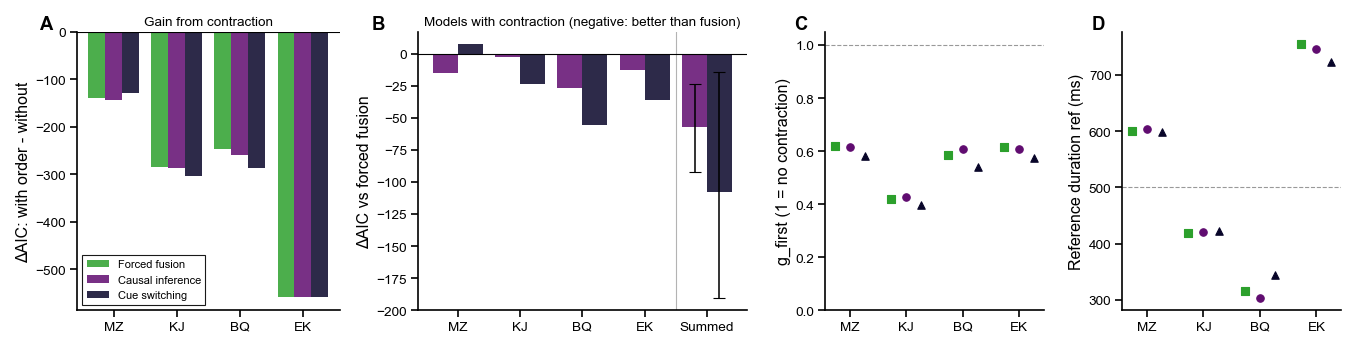

In [4]:
fig = O.fig_fit_summary()
plt.show()

## Predictions per order
One column per noise level × order. Points: data fitted per order (participant: bootstrap 95% CI; group: mean ± SEM; PSEs outside 50–2000 ms not drawn). Lines: each model's expected answers fitted the same way. The y range follows the estimates, so wide intervals can run off the panel.

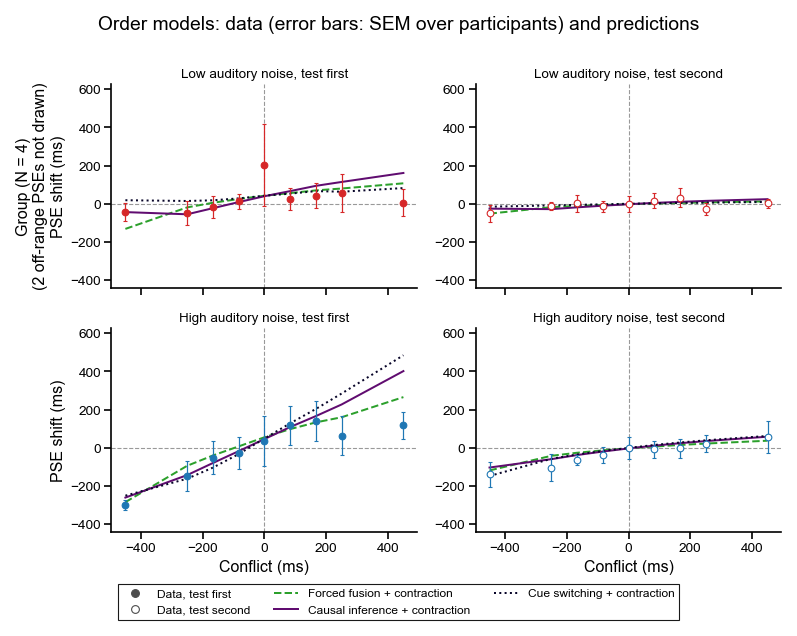

In [5]:
fig = O.fig_predictions("group", width=10, grid=True)
plt.show()

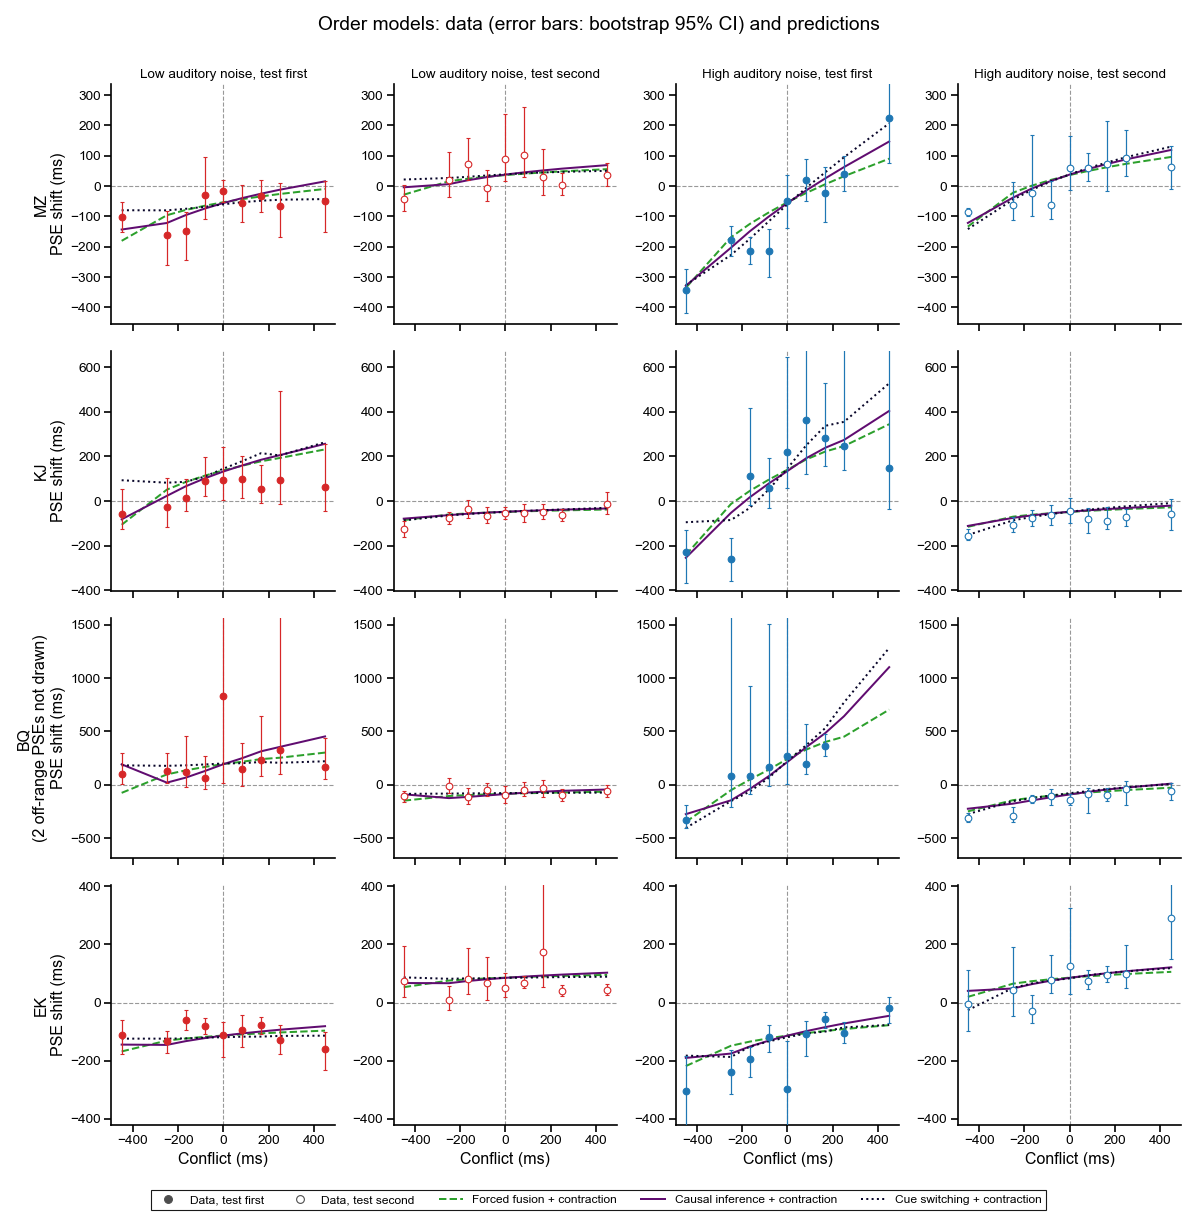

In [6]:
fig = O.fig_predictions("all")
plt.show()

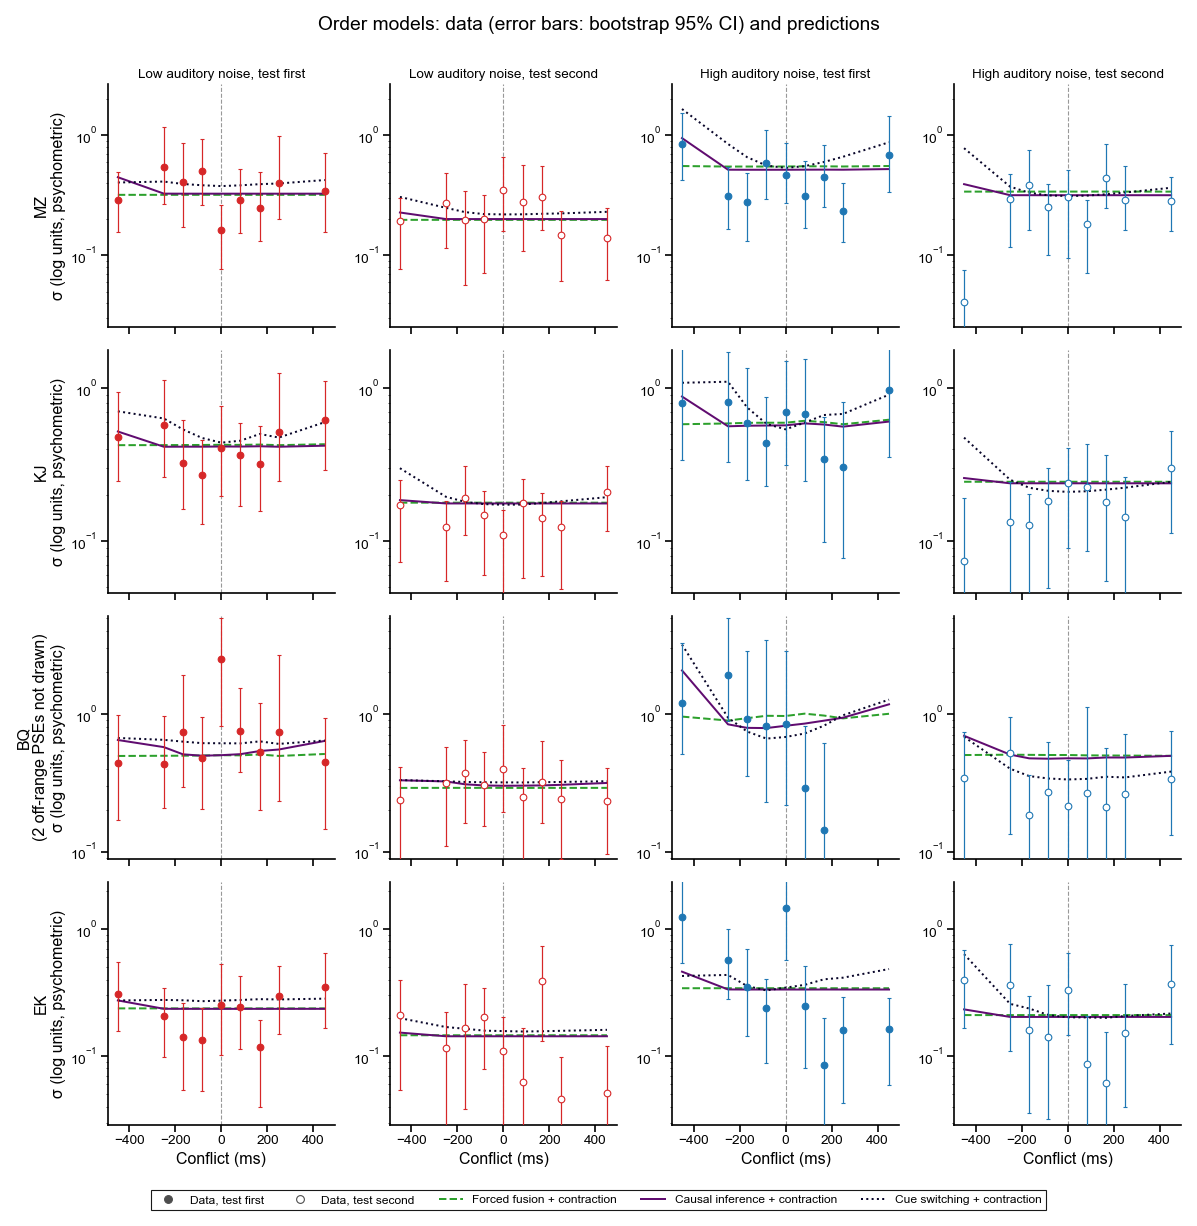

In [7]:
fig = O.fig_predictions("all", col="sigma")
plt.show()

## Explainer
A step-by-step PDF of this model: `docs/order_model_explainer/order_model_explainer.pdf` (rebuild: `python docs/order_model_explainer/make_figures.py`, then `latexmk -pdf` in that folder).